<a href="https://colab.research.google.com/github/luckyKumar37/Deep_learning_project/blob/main/rice_classification/rice_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset,Dataset,DataLoader,random_split
from torchvision import datasets,transforms
from torchsummary import summary
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random


def set_seed(seed=42):
  torch.manual_seed(seed)
  torch.cuda.manual_seed_all(seed)
  random.seed(seed)
  np.random.seed(seed)


set_seed()

device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [4]:
df = pd.read_csv('/content/riceClassification.csv')
df.head()

,id,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
0,1,4537,92.229316,64.012769,0.719916,4677,76.004525,0.657536,273.085,0.764510,1.440796,1
1,2,2872,74.691881,51.400454,0.725553,3015,60.471018,0.713009,208.317,0.831658,1.453137,1
2,3,3048,76.293164,52.043491,0.731211,3132,62.296341,0.759153,210.012,0.868434,1.465950,1
3,4,3073,77.033628,51.928487,0.738639,3157,62.551300,0.783529,210.657,0.870203,1.483456,1
4,5,3693,85.124785,56.374021,0.749282,3802,68.571668,0.769375,230.332,0.874743,1.510000,1


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18185 entries, 0 to 18184
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               18185 non-null  int64  
 1   Area             18185 non-null  int64  
 2   MajorAxisLength  18185 non-null  float64
 3   MinorAxisLength  18185 non-null  float64
 4   Eccentricity     18185 non-null  float64
 5   ConvexArea       18185 non-null  int64  
 6   EquivDiameter    18185 non-null  float64
 7   Extent           18185 non-null  float64
 8   Perimeter        18185 non-null  float64
 9   Roundness        18185 non-null  float64
 10  AspectRation     18185 non-null  float64
 11  Class            18185 non-null  int64  
dtypes: float64(8), int64(4)
memory usage: 1.7 MB


In [6]:
df = df.drop(columns=['id'])
df.sample(5)

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
18056,9429,174.671378,69.661360,0.917032,9752,109.569045,0.644938,406.975,0.715385,2.507436,0
3256,5842,145.807572,51.673280,0.935096,6020,86.245379,0.641978,330.790,0.670914,2.821721,1
17106,8359,158.012446,67.848264,0.903121,8540,103.164962,0.666268,370.413,0.765582,2.328909,0
9810,6493,167.571643,50.974529,0.952610,6737,90.923838,0.796687,366.921,0.606052,3.287360,1
9563,5594,153.172203,47.071526,0.951609,5770,84.394917,0.496847,337.176,0.618328,3.254031,1


In [7]:
df.shape

(18185, 11)

In [8]:
df.describe()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
count,18185.000000,18185.000000,18185.000000,18185.000000,18185.000000,18185.000000,18185.000000,18185.000000,18185.000000,18185.000000,18185.000000
mean,7036.492989,151.680754,59.807851,0.915406,7225.817872,94.132952,0.616653,351.606949,0.707998,2.599081,0.549079
std,1467.197150,12.376402,10.061653,0.030575,1502.006571,9.906250,0.104389,29.500620,0.067310,0.434836,0.497599
min,2522.000000,74.133114,34.409894,0.676647,2579.000000,56.666658,0.383239,197.015000,0.174590,1.358128,0.000000
25%,5962.000000,145.675910,51.393151,0.891617,6125.000000,87.126656,0.538530,333.990000,0.650962,2.208527,0.000000
50%,6660.000000,153.883750,55.724288,0.923259,6843.000000,92.085696,0.601194,353.088000,0.701941,2.602966,1.000000
75%,8423.000000,160.056214,70.156593,0.941372,8645.000000,103.559146,0.695664,373.003000,0.769280,2.964101,1.000000
max,10210.000000,183.211434,82.550762,0.966774,11008.000000,114.016559,0.886573,508.511000,0.904748,3.911845,1.000000


In [9]:
df['Class'].value_counts()

,count
Class,
1,9985
0,8200


In [10]:
X = df.drop(columns=['Class'])
y = df['Class']


X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=42)
X_test,X_val,y_test,y_val = train_test_split(X_test,y_test,test_size=0.5,random_state=42)

print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")
print(f"X_val: {X_val.shape}")



X_train: (12729, 10)
X_test: (2728, 10)
X_val: (2728, 10)


In [11]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
X_val = scaler.transform(X_val)

X_train

array([[ 1.43940608,  0.91908991,  1.20534871, ...,  0.99714806,
         1.24052646, -0.76298605],
       [ 1.60855462,  0.88236942,  1.48679495, ...,  1.48488677,
         0.69492271, -0.9743977 ],
       [ 1.3493754 ,  0.87014192,  1.21627294, ...,  1.47101807,
         0.26365369, -0.79031735],
       ...,
       [-0.29300243, -2.03506884,  0.7993019 , ..., -1.25627989,
         1.9534134 , -1.69108419],
       [-0.37280235, -0.34315723, -0.28210044, ..., -0.46836825,
         0.10113424, -0.02597983],
       [ 1.02949367,  0.4763583 ,  0.97924292, ...,  0.87175466,
         0.68463494, -0.77406934]])

In [12]:
class dataset(Dataset):
  def __init__(self,X,y):
    self.X = torch.tensor(X,dtype=torch.float32).to(device)
    self.y = torch.tensor(np.array(y),dtype=torch.float32).to(device)

  def __len__(self):
    return len(self.X)

  def __getitem__(self,idx):
    return self.X[idx],self.y[idx]




In [13]:
train_dataset = dataset(X_train,y_train)
test_dataset = dataset(X_test,y_test)
val_dataset = dataset(X_val,y_val)

In [14]:
train_loader = DataLoader(train_dataset,batch_size=32,shuffle=True)
test_loader = DataLoader(test_dataset,batch_size=32,shuffle=False)
val_loader = DataLoader(val_dataset,batch_size=32,shuffle=False)

In [15]:
class model(nn.Module):
  def __init__(self,input_shape):
    super().__init__()

    self.network = nn.Sequential(
        nn.Linear(input_shape,32),
        nn.ReLU(),
        nn.Linear(32,16),
        nn.ReLU(),
        nn.Linear(16,1),
        nn.Sigmoid()
    )

  def forward(self,x):

    return self.network(x)



In [16]:
model = model(X_train.shape[1]).to(device)

criterion = nn.BCELoss()

optimizer = optim.Adam(model.parameters(),lr=1e-3)


In [17]:
summary(model,(X_train.shape[1],))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                   [-1, 32]             352
              ReLU-2                   [-1, 32]               0
            Linear-3                   [-1, 16]             528
              ReLU-4                   [-1, 16]               0
            Linear-5                    [-1, 1]              17
           Sigmoid-6                    [-1, 1]               0
Total params: 897
Trainable params: 897
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00
----------------------------------------------------------------


In [19]:
total_train_loss_plot = []
total_train_acc_plot = []
total_val_loss_plot = []
total_val_acc_plot = []

epochs = 10

for epoch in range(epochs):
  total_loss_train = 0
  total_acc_train = 0
  total_loss_val = 0
  total_acc_val = 0

  # training
  for input,label in train_loader:

    model.train()

    prediction = model(input).squeeze(1)

    loss = criterion(prediction,label)

    total_loss_train += loss

    acc = ((prediction).round() == label).sum().item()

    total_acc_train += acc

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()


  #validation

  model.eval()

  with torch.no_grad():

    for input,label in val_loader:

      prediction = model(input).squeeze(1)

      loss = criterion(prediction,label)

      total_loss_val += loss

      acc = ((prediction.round()) == label).sum().item()

      total_acc_val += acc

  total_train_loss_plot.append(round(total_loss_train.item()/1000, 4))
  total_val_loss_plot.append(round(total_loss_val.item()/1000, 4))
  total_train_acc_plot.append(round(total_acc_train/(train_dataset.__len__())*100, 4))
  total_val_acc_plot.append(round(total_acc_val/(val_dataset.__len__())*100, 4))

  print(f'''Epoch no. {epoch + 1} Train Loss: {total_loss_train.item()/1000:.4f} Train Accuracy: {(total_acc_train/(train_dataset.__len__())*100):.4f} Validation Loss: {total_loss_val.item()/1000:.4f} Validation Accuracy: {(total_acc_val/(val_dataset.__len__())*100):.4f}''')
  print("="*50)

Epoch no. 1 Train Loss: 0.0152 Train Accuracy: 98.7745 Validation Loss: 0.0036 Validation Accuracy: 98.5704
Epoch no. 2 Train Loss: 0.0147 Train Accuracy: 98.8294 Validation Loss: 0.0031 Validation Accuracy: 98.6804
Epoch no. 3 Train Loss: 0.0142 Train Accuracy: 98.8766 Validation Loss: 0.0031 Validation Accuracy: 98.6437
Epoch no. 4 Train Loss: 0.0140 Train Accuracy: 98.8687 Validation Loss: 0.0031 Validation Accuracy: 98.6437
Epoch no. 5 Train Loss: 0.0137 Train Accuracy: 98.8609 Validation Loss: 0.0031 Validation Accuracy: 98.6070
Epoch no. 6 Train Loss: 0.0136 Train Accuracy: 98.9001 Validation Loss: 0.0030 Validation Accuracy: 98.6804
Epoch no. 7 Train Loss: 0.0135 Train Accuracy: 98.8844 Validation Loss: 0.0030 Validation Accuracy: 98.7170
Epoch no. 8 Train Loss: 0.0132 Train Accuracy: 98.9001 Validation Loss: 0.0030 Validation Accuracy: 98.6804
Epoch no. 9 Train Loss: 0.0132 Train Accuracy: 98.9159 Validation Loss: 0.0031 Validation Accuracy: 98.7170
Epoch no. 10 Train Loss: 0.0

In [20]:
# testing

model.eval()

with torch.no_grad():
  total_loss_test = 0
  total_acc_test = 0

  for input,label in test_loader:

    prediction = model(input).squeeze(1)

    loss = criterion(prediction,label)

    total_loss_test += loss

    acc = ((prediction).round() == label).sum().item()

    total_acc_test += acc

print(f"Accuracy Score is: {round((total_acc_test/X_test.shape[0])*100, 2)}%")





Accuracy Score is: 99.27%


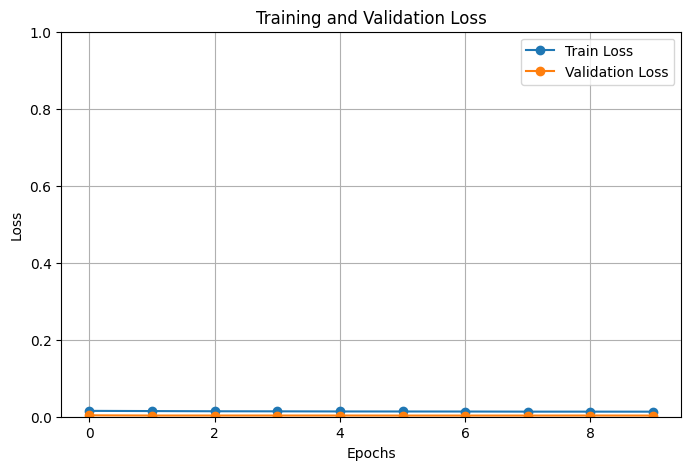

In [27]:
plt.figure(figsize=(8, 5))
plt.plot(total_train_loss_plot, label='Train Loss', marker='o')
plt.plot(total_val_loss_plot, label='Validation Loss', marker='o')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.ylim([0, 1])
plt.show()

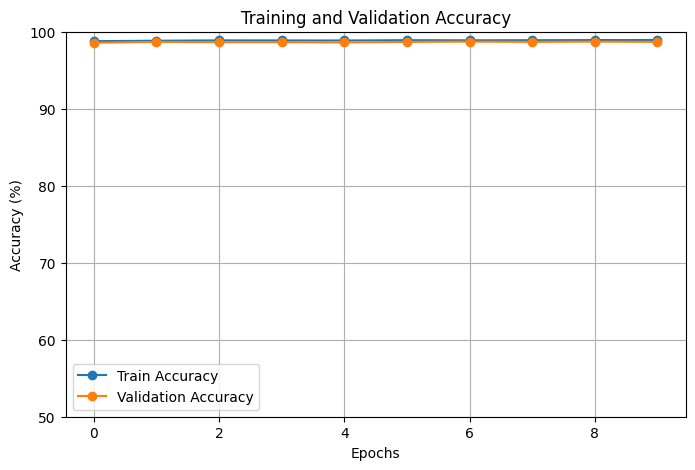

In [29]:
plt.figure(figsize=(8, 5))
plt.plot(total_train_acc_plot, label='Train Accuracy', marker='o')
plt.plot(total_val_acc_plot, label='Validation Accuracy', marker='o')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)
plt.ylim([50,100])
plt.show()